# Diabetic Retinopathy Severity Classification with EfficientNetB0

Five-class grading of retinal fundus images (**No_DR, Mild, Moderate, Severe, Proliferate_DR**) using transfer learning, with a focus on **referable DR** detection (Moderate or worse).

**Dataset:** [APTOS-derived, 224x224 Gaussian-filtered](https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered) (3,662 images)

## Contents
1. Setup
2. Data
3. Helper functions
4. Experiment 1: Baseline (frozen backbone + augmentation)
5. Experiment 2: Class-weighted loss
6. Experiment 3: Fine-tuning the last 30 layers
7. Experiment 4: Balanced sampling
8. Model comparison
9. Grad-CAM explainability

> Run all cells top to bottom. Experiments 3 and 4 continue training the model from the previous experiment.

## 1. Setup

In [ ]:
!pip install -q kagglehub

In [ ]:
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---- Configuration ----
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 5

# Save models / metrics / figures to Google Drive (set False to save under /content instead)
USE_DRIVE = True

tf.keras.utils.set_random_seed(SEED)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/DR_Project"
else:
    OUTPUT_DIR = "/content/DR_Project"

os.makedirs(os.path.join(OUTPUT_DIR, "GradCAM"), exist_ok=True)
print("Outputs will be saved to:", OUTPUT_DIR)

Mounted at /content/drive
Outputs will be saved to: /content/drive/MyDrive/DR_Project


## 2. Data

### 2.1 Download dataset

In [ ]:
path = kagglehub.dataset_download(
    "sovitrath/diabetic-retinopathy-224x224-gaussian-filtered"
)

# Locate the folder that directly contains the five class sub-folders
REQUIRED = {"No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"}
DATASET = next(
    root for root, dirs, _ in os.walk(path) if REQUIRED.issubset(dirs)
)

print("Dataset path:", DATASET)
for cls in sorted(REQUIRED):
    n = len(os.listdir(os.path.join(DATASET, cls)))
    print(f"  {cls:<15} {n} images")

100%|██████████| 427M/427M [00:03<00:00, 135MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered/versions/2/gaussian_filtered_images/gaussian_filtered_images
  Mild            370 images
  Moderate        999 images
  No_DR           1805 images
  Proliferate_DR  295 images
  Severe          193 images


### 2.2 Train / validation split
80/20 split with a fixed seed. Class indices follow alphabetical folder order:
`0 = Mild, 1 = Moderate, 2 = No_DR, 3 = Proliferate_DR, 4 = Severe`.

In [ ]:
def load_split(subset):
    return tf.keras.utils.image_dataset_from_directory(
        DATASET,
        validation_split=0.2,
        subset=subset,
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
    )

train_ds = load_split("training")
val_ds = load_split("validation")

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", dict(enumerate(class_names)))

# Referable DR = Moderate or worse (derived from names, so it is independent of folder order)
REFERABLE = [class_names.index(c) for c in ("Moderate", "Severe", "Proliferate_DR")]
print("Referable DR class indices:", REFERABLE)

Found 3662 files belonging to 5 classes.
Using 2930 files for training.
Found 3662 files belonging to 5 classes.
Using 732 files for validation.
Classes: {0: 'Mild', 1: 'Moderate', 2: 'No_DR', 3: 'Proliferate_DR', 4: 'Severe'}
Referable DR class indices: [1, 4, 3]


In [ ]:
# Class distribution of the training set and balanced class weights
train_labels = np.concatenate([y.numpy() for _, y in train_ds])
counts = np.bincount(train_labels, minlength=NUM_CLASSES)

weights = compute_class_weight(
    "balanced", classes=np.arange(NUM_CLASSES), y=train_labels
)
class_weights = {i: float(w) for i, w in enumerate(weights)}

print(f"{'Class':<16}{'Count':>7}{'Weight':>9}")
for i, name in enumerate(class_names):
    print(f"{name:<16}{counts[i]:>7}{class_weights[i]:>9.4f}")

Class             Count   Weight
Mild                311   1.8842
Moderate            794   0.7380
No_DR              1442   0.4064
Proliferate_DR      236   2.4831
Severe              147   3.9864


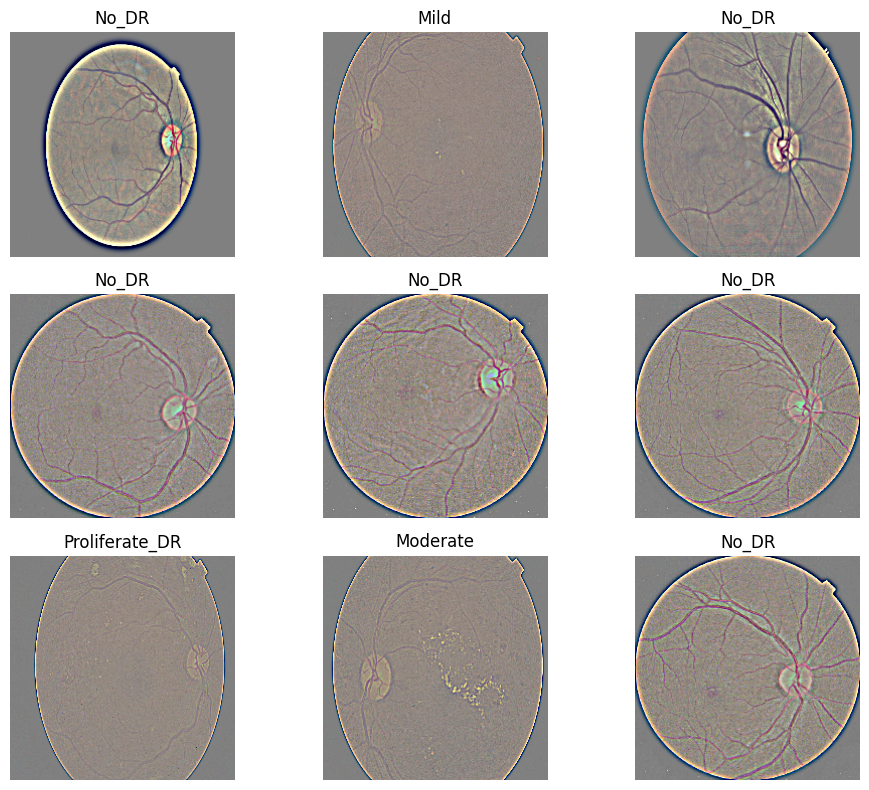

In [ ]:
# Speed up input pipeline
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Sample images
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Helper functions

In [ ]:
augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
    ],
    name="augmentation",
)


def build_model(use_augmentation=True, learning_rate=1e-3):
    """EfficientNetB0 (frozen, ImageNet weights) + GAP + Dropout + softmax head."""
    backbone = EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
    )
    backbone.trainable = False

    stack = [layers.Input(shape=(*IMG_SIZE, 3))]
    if use_augmentation:
        stack.append(augmentation)
    stack += [
        backbone,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ]

    model = models.Sequential(stack)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model, backbone


def plot_history(history, title):
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.show()


def save_model(model, filename):
    model.save(os.path.join(OUTPUT_DIR, filename))
    print("Saved:", filename)

In [ ]:
def predict_dataset(model, ds):
    """Return (y_true, y_pred).

    Labels and predictions are collected in the same pass over `ds`, so they stay
    aligned even though the dataset reshuffles on every iteration.
    """
    y_true, y_pred = [], []
    for images, labels in ds:
        probs = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(probs, axis=1))
    return np.array(y_true), np.array(y_pred)


def referable_metrics(y_true, y_pred):
    """Binary metrics for referable DR (Moderate or worse)."""
    t = np.isin(y_true, REFERABLE).astype(int)
    p = np.isin(y_pred, REFERABLE).astype(int)
    tn, fp, fn, tp = confusion_matrix(t, p).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = (2 * precision * sensitivity / (precision + sensitivity)
          if (precision + sensitivity) else 0.0)
    return {
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1 Score": f1,
    }


# Collected for the comparison table in section 8
results = {}


def evaluate(model, name, tag):
    """Full evaluation on the validation set: report, confusion matrix, referable-DR metrics.

    Saves the confusion matrix (PNG) and the report / referable metrics (CSV) to OUTPUT_DIR.
    """
    y_true, y_pred = predict_dataset(model, val_ds)
    labels = list(range(NUM_CLASSES))

    # Per-class report
    print(classification_report(
        y_true, y_pred, labels=labels, target_names=class_names,
        digits=4, zero_division=0,
    ))
    report = classification_report(
        y_true, y_pred, labels=labels, target_names=class_names,
        output_dict=True, zero_division=0,
    )
    pd.DataFrame(report).T.to_csv(os.path.join(OUTPUT_DIR, f"{tag}_classification_report.csv"))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{name} - Confusion Matrix")
    plt.savefig(os.path.join(OUTPUT_DIR, f"{tag}_confusion_matrix.png"),
                dpi=300, bbox_inches="tight")
    plt.show()

    # Referable DR
    ref = referable_metrics(y_true, y_pred)
    pd.DataFrame([ref]).to_csv(os.path.join(OUTPUT_DIR, f"{tag}_referable_DR_metrics.csv"), index=False)
    print("Referable DR:", {k: round(v, 4) for k, v in ref.items()})

    results[name] = {
        "Accuracy": report["accuracy"],
        "Macro F1": report["macro avg"]["f1-score"],
        **ref,
    }
    return y_true, y_pred

## 4. Experiment 1: Baseline
Frozen EfficientNetB0 backbone with data augmentation, trained with plain cross-entropy.

In [ ]:
baseline_model, baseline_backbone = build_model(use_augmentation=True, learning_rate=1e-3)
baseline_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 125ms/step - accuracy: 0.6437 - loss: 0.9835 - val_accuracy: 0.7172 - val_loss: 0.8422
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.7331 - loss: 0.7563 - val_accuracy: 0.7172 - val_loss: 0.7942
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.7474 - loss: 0.7146 - val_accuracy: 0.7240 - val_loss: 0.7617
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - accuracy: 0.7502 - loss: 0.6895 - val_accuracy: 0.7322 - val_loss: 0.7471
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - accuracy: 0.7543 - loss: 0.6731 - val_accuracy: 0.7391 - val_loss: 0.7092


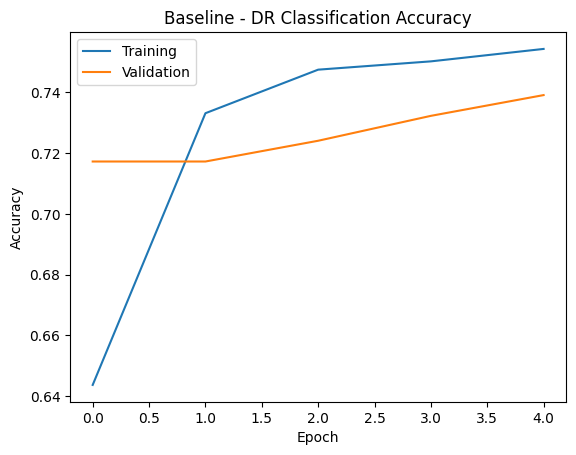

In [ ]:
history_baseline = baseline_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
plot_history(history_baseline, "Baseline - DR Classification Accuracy")

                precision    recall  f1-score   support

          Mild     0.4615    0.2034    0.2824        59
      Moderate     0.5559    0.8732    0.6793       205
         No_DR     0.9115    0.9642    0.9371       363
Proliferate_DR     0.0000    0.0000    0.0000        59
        Severe     0.0000    0.0000    0.0000        46

      accuracy                         0.7391       732
     macro avg     0.3858    0.4081    0.3798       732
  weighted avg     0.6449    0.7391    0.6777       732



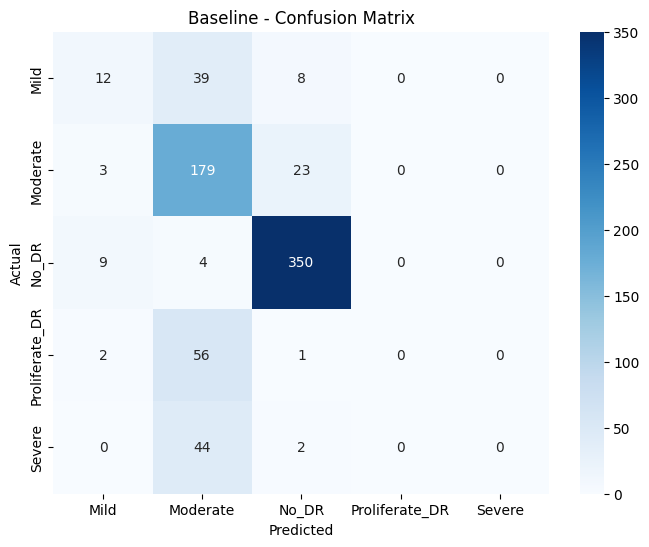

Referable DR: {'Sensitivity': np.float64(0.9), 'Specificity': np.float64(0.8981), 'Precision': np.float64(0.8665), 'F1 Score': np.float64(0.8829)}
Saved: DR_EfficientNetB0_baseline.keras


In [ ]:
evaluate(baseline_model, "Baseline", "baseline")
save_model(baseline_model, "DR_EfficientNetB0_baseline.keras")

## 5. Experiment 2: Class-weighted loss
The dataset is heavily imbalanced (No_DR dominates). Each class is weighted inversely to its frequency.
Two variants are compared: **without** and **with** data augmentation.

### 5.1 Class-weighted, no augmentation

In [ ]:
cw_model, cw_backbone = build_model(use_augmentation=False)
history_cw = cw_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weights
)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 59s 353ms/step - accuracy: 0.5256 - loss: 1.3615 - val_accuracy: 0.6940 - val_loss: 0.9246
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.6430 - loss: 1.1437 - val_accuracy: 0.6421 - val_loss: 0.8773
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.6672 - loss: 1.0894 - val_accuracy: 0.7350 - val_loss: 0.7641
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.6853 - loss: 1.0222 - val_accuracy: 0.7036 - val_loss: 0.7965
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.6962 - loss: 1.0116 - val_accuracy: 0.7172 - val_loss: 0.7555


                precision    recall  f1-score   support

          Mild     0.3520    0.7458    0.4783        59
      Moderate     0.7552    0.5268    0.6207       205
         No_DR     0.9293    0.9421    0.9357       363
Proliferate_DR     0.4000    0.1695    0.2381        59
        Severe     0.2958    0.4565    0.3590        46

      accuracy                         0.7172       732
     macro avg     0.5465    0.5682    0.5263       732
  weighted avg     0.7516    0.7172    0.7181       732



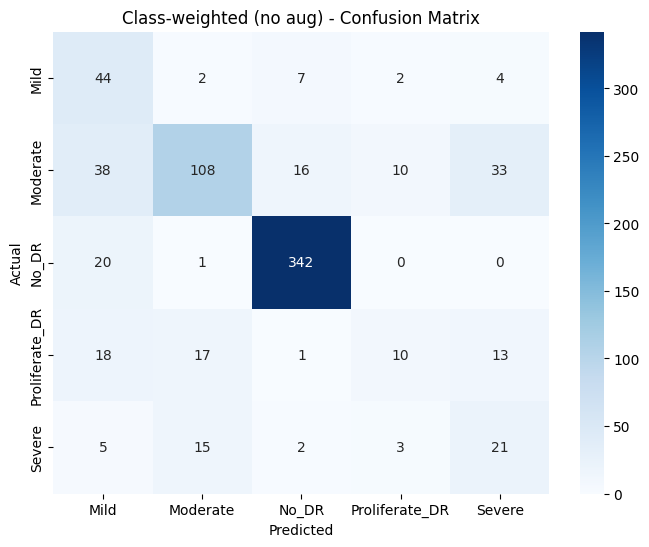

Referable DR: {'Sensitivity': np.float64(0.7419), 'Specificity': np.float64(0.9787), 'Precision': np.float64(0.9623), 'F1 Score': np.float64(0.8379)}
Saved: DR_EfficientNetB0_classweighted.keras


In [ ]:
evaluate(cw_model, "Class-weighted (no aug)", "classweighted_noaug")
save_model(cw_model, "DR_EfficientNetB0_classweighted.keras")

### 5.2 Class-weighted + augmentation

In [ ]:
cw_aug_model, cw_aug_backbone = build_model(use_augmentation=True)
history_cw_aug = cw_aug_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weights
)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 126ms/step - accuracy: 0.5389 - loss: 1.3335 - val_accuracy: 0.6844 - val_loss: 0.8947
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 93ms/step - accuracy: 0.6348 - loss: 1.1768 - val_accuracy: 0.7104 - val_loss: 0.8404
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 103ms/step - accuracy: 0.6679 - loss: 1.1099 - val_accuracy: 0.7104 - val_loss: 0.8050
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.6751 - loss: 1.0723 - val_accuracy: 0.7254 - val_loss: 0.8021
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.6799 - loss: 1.0540 - val_accuracy: 0.7404 - val_loss: 0.7913


                precision    recall  f1-score   support

          Mild     0.3636    0.4746    0.4118        59
      Moderate     0.6332    0.8000    0.7069       205
         No_DR     0.9407    0.9174    0.9289       363
Proliferate_DR     0.3636    0.0678    0.1143        59
        Severe     0.4194    0.2826    0.3377        46

      accuracy                         0.7404       732
     macro avg     0.5441    0.5085    0.4999       732
  weighted avg     0.7288    0.7404    0.7222       732



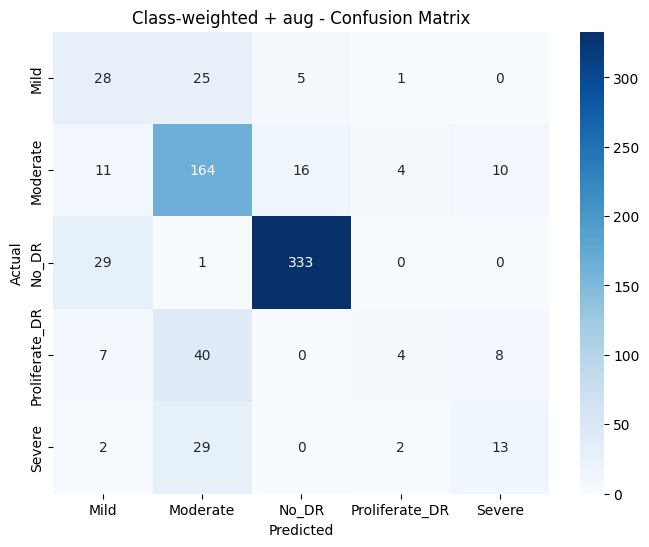

Referable DR: {'Sensitivity': np.float64(0.8839), 'Specificity': np.float64(0.936), 'Precision': np.float64(0.9103), 'F1 Score': np.float64(0.8969)}


(array([2, 0, 2, 2, 1, 1, 1, 0, 2, 0, 0, 2, 4, 1, 2, 1, 1, 2, 2, 0, 1, 1,
        2, 4, 3, 1, 1, 0, 1, 1, 2, 1, 2, 2, 2, 1, 2, 0, 1, 2, 1, 1, 2, 1,
        3, 1, 3, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 3, 2, 1, 2, 0, 2, 1, 2, 2,
        2, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 1, 2, 2, 0, 3, 4, 1, 4, 2, 2,
        1, 0, 1, 3, 2, 4, 2, 2, 3, 1, 2, 1, 2, 3, 1, 2, 1, 0, 0, 2, 1, 2,
        2, 1, 3, 2, 4, 2, 2, 4, 2, 2, 2, 1, 2, 1, 2, 3, 2, 1, 2, 2, 2, 2,
        2, 2, 2, 4, 0, 0, 1, 3, 2, 2, 2, 2, 2, 4, 1, 0, 2, 4, 3, 1, 2, 0,
        1, 0, 1, 2, 1, 2, 2, 2, 3, 3, 2, 1, 1, 2, 1, 1, 2, 2, 1, 1, 2, 2,
        1, 1, 4, 2, 1, 0, 3, 2, 1, 2, 2, 1, 2, 2, 1, 2, 3, 3, 1, 2, 1, 3,
        1, 2, 2, 2, 2, 1, 1, 1, 4, 4, 2, 2, 4, 2, 2, 2, 2, 3, 3, 1, 1, 2,
        2, 0, 1, 3, 2, 2, 1, 1, 2, 2, 1, 2, 2, 2, 0, 3, 4, 2, 2, 2, 2, 2,
        3, 2, 2, 2, 1, 1, 0, 4, 1, 3, 1, 1, 2, 2, 1, 1, 2, 3, 4, 1, 2, 4,
        1, 1, 4, 2, 2, 4, 2, 1, 0, 2, 0, 2, 1, 2, 3, 1, 3, 2, 1, 2, 2, 1,
        2, 1, 1, 2, 1, 0, 1, 0, 2, 1, 

In [ ]:
evaluate(cw_aug_model, "Class-weighted + aug", "classweighted_aug")

## 6. Experiment 3: Fine-tuning
Continue from the class-weighted + augmentation model: unfreeze the last 30 backbone layers
(BatchNorm layers stay frozen) and train with a very low learning rate.

In [ ]:
FINE_TUNE_LAYERS = 30

cw_aug_backbone.trainable = True
for layer in cw_aug_backbone.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in cw_aug_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile so the new trainable flags take effect
cw_aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("Backbone layers:", len(cw_aug_backbone.layers))
print("Trainable backbone layers:", sum(l.trainable for l in cw_aug_backbone.layers))

Backbone layers: 238
Trainable backbone layers: 23


Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 127ms/step - accuracy: 0.7003 - loss: 1.0270 - val_accuracy: 0.7295 - val_loss: 0.7765
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.7031 - loss: 1.0291 - val_accuracy: 0.7281 - val_loss: 0.7748
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.7102 - loss: 0.9980 - val_accuracy: 0.7336 - val_loss: 0.7652
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.7027 - loss: 0.9970 - val_accuracy: 0.7336 - val_loss: 0.7610
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.7116 - loss: 0.9829 - val_accuracy: 0.7377 - val_loss: 0.7682


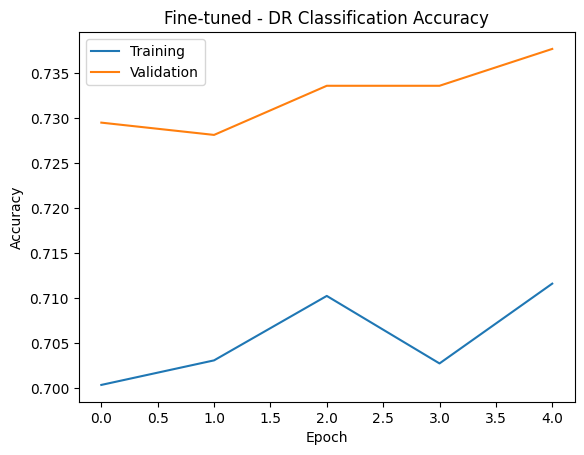

In [ ]:
history_finetune = cw_aug_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weights
)
plot_history(history_finetune, "Fine-tuned - DR Classification Accuracy")

                precision    recall  f1-score   support

          Mild     0.4000    0.5424    0.4604        59
      Moderate     0.6761    0.7024    0.6890       205
         No_DR     0.9417    0.9339    0.9378       363
Proliferate_DR     0.4000    0.0339    0.0625        59
        Severe     0.3108    0.5000    0.3833        46

      accuracy                         0.7377       732
     macro avg     0.5457    0.5425    0.5066       732
  weighted avg     0.7403    0.7377    0.7242       732



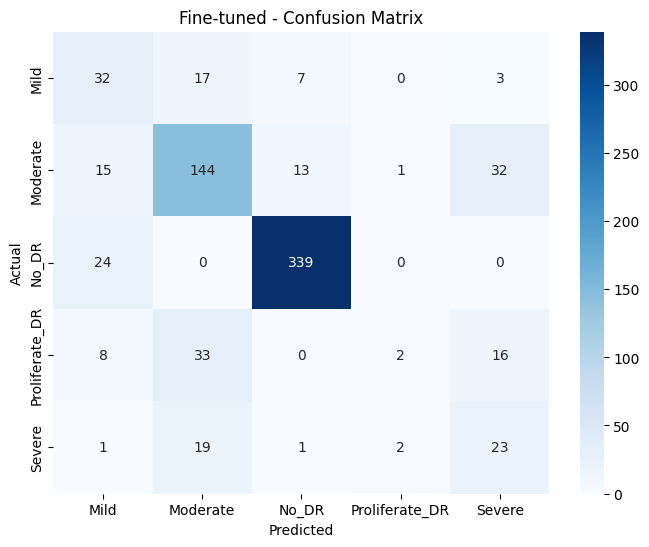

Referable DR: {'Sensitivity': np.float64(0.8774), 'Specificity': np.float64(0.9526), 'Precision': np.float64(0.9315), 'F1 Score': np.float64(0.9037)}
Saved: DR_EfficientNetB0_finetuned.keras


In [ ]:
evaluate(cw_aug_model, "Fine-tuned", "finetuned")
save_model(cw_aug_model, "DR_EfficientNetB0_finetuned.keras")

## 7. Experiment 4: Balanced sampling
Continue training the fine-tuned model on a stream that draws **equally from every class**
(oversampling minority classes on the fly). Class weights are not used here, since the batches are already balanced.

In [ ]:
# One repeating dataset per class, sampled with equal probability
unbatched = train_ds.unbatch()

def class_stream(c):
    return unbatched.filter(lambda image, label: tf.equal(label, c)).repeat()

per_class = [class_stream(c) for c in range(NUM_CLASSES)]

balanced_train_ds = (
    tf.data.Dataset.sample_from_datasets(
        per_class, weights=[1.0 / NUM_CLASSES] * NUM_CLASSES, seed=SEED
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# One "epoch" = as many samples as a fully balanced set (largest class x number of classes)
steps_per_epoch = int(np.ceil(counts.max() * NUM_CLASSES / BATCH_SIZE))
print("Steps per epoch:", steps_per_epoch)

Steps per epoch: 226


Epoch 1/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 101s 415ms/step - accuracy: 0.6026 - loss: 0.9678 - val_accuracy: 0.7350 - val_loss: 0.7758
Epoch 2/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 92s 410ms/step - accuracy: 0.6098 - loss: 0.9515 - val_accuracy: 0.7227 - val_loss: 0.7948
Epoch 3/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 93s 412ms/step - accuracy: 0.6097 - loss: 0.9438 - val_accuracy: 0.7350 - val_loss: 0.7837
Epoch 4/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 91s 404ms/step - accuracy: 0.6126 - loss: 0.9339 - val_accuracy: 0.7322 - val_loss: 0.7893
Epoch 5/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 92s 410ms/step - accuracy: 0.6309 - loss: 0.9097 - val_accuracy: 0.7432 - val_loss: 0.7572


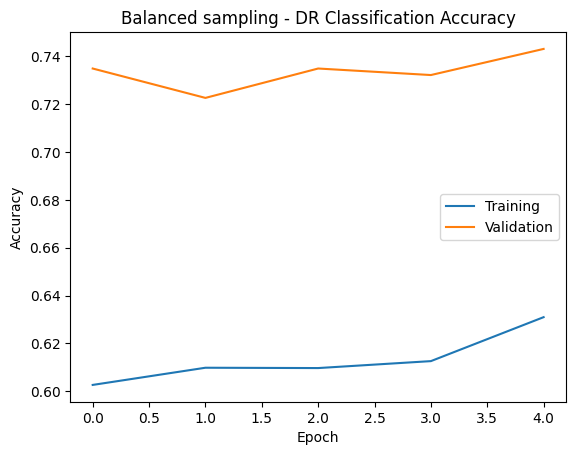

In [ ]:
history_balanced = cw_aug_model.fit(
    balanced_train_ds,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=val_ds,
)
plot_history(history_balanced, "Balanced sampling - DR Classification Accuracy")

                precision    recall  f1-score   support

          Mild     0.4154    0.4576    0.4355        59
      Moderate     0.6729    0.7024    0.6874       205
         No_DR     0.9577    0.9366    0.9471       363
Proliferate_DR     0.4444    0.1356    0.2078        59
        Severe     0.3125    0.5435    0.3968        46

      accuracy                         0.7432       732
     macro avg     0.5606    0.5552    0.5349       732
  weighted avg     0.7523    0.7432    0.7389       732



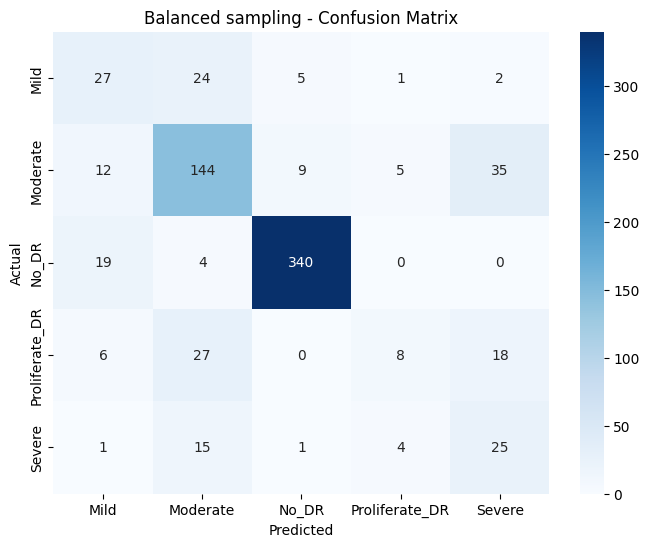

Referable DR: {'Sensitivity': np.float64(0.9065), 'Specificity': np.float64(0.9265), 'Precision': np.float64(0.9006), 'F1 Score': np.float64(0.9035)}
Saved: DR_EfficientNetB0_balanced.keras


In [ ]:
evaluate(cw_aug_model, "Balanced sampling", "balanced")
save_model(cw_aug_model, "DR_EfficientNetB0_balanced.keras")

## 8. Model comparison

In [ ]:
comparison = pd.DataFrame(results).T.round(4)
comparison.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"))
comparison

,Accuracy,Macro F1,Sensitivity,Specificity,Precision,F1 Score
Baseline,0.7391,0.3798,0.9000,0.8981,0.8665,0.8829
Class-weighted (no aug),0.7172,0.5263,0.7419,0.9787,0.9623,0.8379
Class-weighted + aug,0.7404,0.4999,0.8839,0.9360,0.9103,0.8969
Fine-tuned,0.7377,0.5066,0.8774,0.9526,0.9315,0.9037
Balanced sampling,0.7432,0.5349,0.9065,0.9265,0.9006,0.9035


## 9. Grad-CAM explainability
Highlights the image regions that drive the predicted class (computed on the final model's last conv layer).

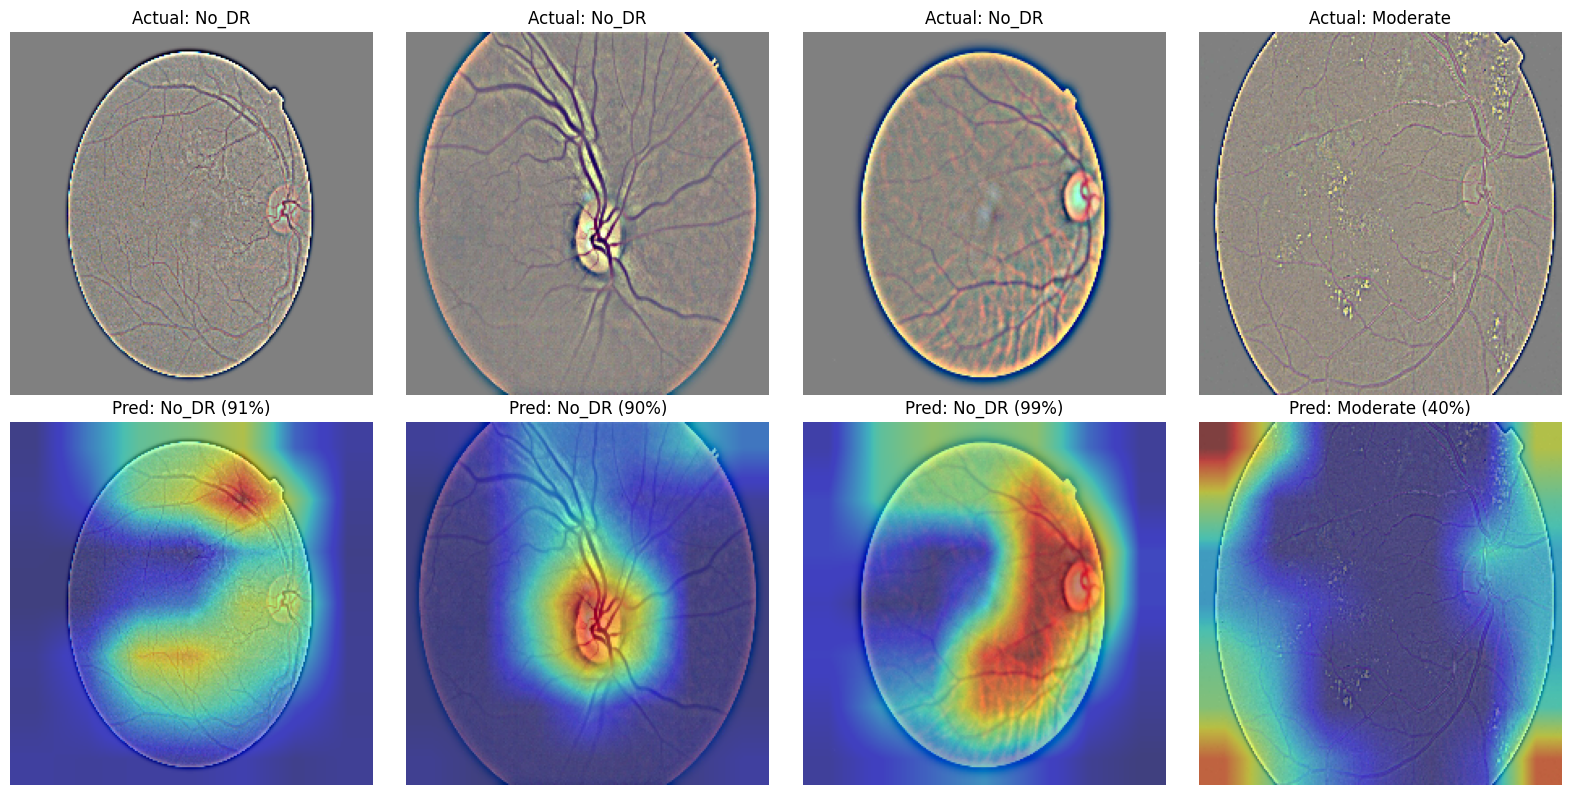

In [ ]:
def make_gradcam(backbone, dense, image):
    """Grad-CAM heatmap for the predicted class of one image (shape [1, H, W, 3])."""
    with tf.GradientTape() as tape:
        feature_maps = backbone(image, training=False)      # last conv feature maps
        tape.watch(feature_maps)
        pooled = tf.reduce_mean(feature_maps, axis=[1, 2])  # global average pooling
        predictions = dense(pooled)
        class_id = tf.argmax(predictions[0])
        score = predictions[:, class_id]

    grads = tape.gradient(score, feature_maps)
    channel_weights = tf.reduce_mean(grads, axis=[1, 2])
    cam = tf.reduce_sum(channel_weights[:, None, None, :] * feature_maps, axis=-1)
    cam = tf.maximum(cam, 0)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam[0].numpy(), int(class_id.numpy()), predictions[0].numpy()


def show_gradcam(model, backbone, ds, n=4, save_as=None):
    """Plot original vs. Grad-CAM overlay for the first `n` images of one validation batch."""
    dense = model.layers[-1]
    images, labels = next(iter(ds))

    plt.figure(figsize=(4 * n, 8))
    for i in range(n):
        image = images[i:i + 1]
        heatmap, pred, probs = make_gradcam(backbone, dense, image)

        shown = image[0].numpy().astype("uint8")
        heatmap = tf.image.resize(heatmap[..., None], shown.shape[:2]).numpy().squeeze()

        plt.subplot(2, n, i + 1)
        plt.imshow(shown)
        plt.title(f"Actual: {class_names[labels[i]]}")
        plt.axis("off")

        plt.subplot(2, n, n + i + 1)
        plt.imshow(shown)
        plt.imshow(heatmap, cmap="jet", alpha=0.5)
        plt.title(f"Pred: {class_names[pred]} ({probs[pred]:.0%})")
        plt.axis("off")

    plt.tight_layout()
    if save_as:
        plt.savefig(os.path.join(OUTPUT_DIR, "GradCAM", save_as), dpi=300, bbox_inches="tight")
    plt.show()


show_gradcam(cw_aug_model, cw_aug_backbone, val_ds, n=4, save_as="final_model_gradcam.png")